## Ejemplo 0: Introducción a Keras

In [1]:
from tensorflow import keras
from tensorflow.keras import layers

## Funciones de Activación

Pueden ser `relu`, `sigmoid`, `softmax`, `tanh`, `elu`, `linear`, `swish`, `selu`, etc. Para ver todas: https://www.tensorflow.org/api_docs/python/tf/keras/activations


In [2]:
# Se define con layers.Activation
activation_layer = layers.Activation('relu')
# Una vez definida se comporta como cualquier función

Ejemplo de gráfico de las funciones de activación

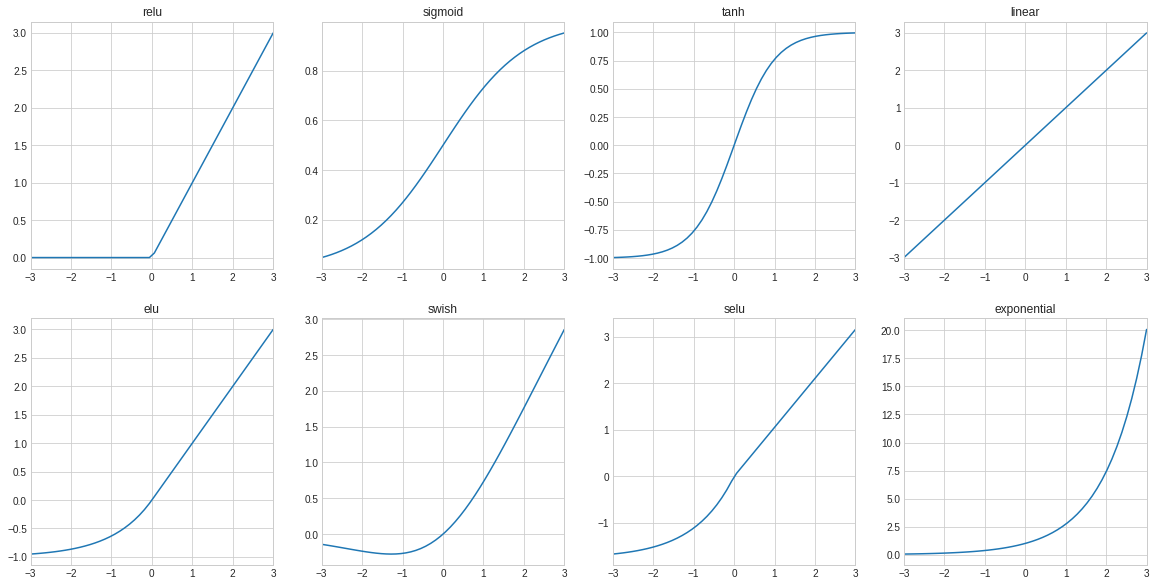

In [3]:
import tensorflow as tf
import matplotlib.pyplot as plt

x = tf.linspace(-3, 3, 50)

names = ['relu', 'sigmoid', 'tanh', 'linear', 'elu', 'swish', 'selu', 'exponential']

plt.figure(figsize=(20,10))
plt.style.use('seaborn-whitegrid')
for i in range(len(names)):
    activation = layers.Activation(names[i], dtype='float64') 
    y = activation(x)
    plt.subplot(2,4,i+1)
    plt.plot(x, y); plt.xlim(-3, 3)
    plt.title(names[i])
plt.show()

## Capas de una Red Neuronal

Red Neuronal con 1 sola neurona

* 3 atributos de entrada
* 1 sola salida (activación sigmoidea)


In [4]:
# El término "units" es opcional
model = keras.Sequential([
    layers.Dense(units=1, activation='sigmoid', input_shape=[3])
])

Red neuronal con 4 capas:
* Atributos de entrada: 8
* Capa 1: 256 neuronas (activación ReLU)
* Capa 2: 512 neuronas (activación ReLU)
* Capa 3: 128 neuronas (activación ReLU)
* Capa 4: 1 neurona (activación lineal = sin activación)

In [5]:
# Forma 1: indicando la activación dentro de cada capa
model = keras.Sequential([
    layers.Dense(units=256, activation='relu', input_shape=[8]),
    layers.Dense(units=512, activation='relu'),
    layers.Dense(units=128, activation='relu'),
    layers.Dense(units=1)
])

In [6]:
# Forma 2: Separando las activaciones de las capas
model = keras.Sequential([
    layers.Dense(units=256, input_shape=[8]),
    layers.Activation('relu'),
    layers.Dense(units=512),
    layers.Activation('relu'),
    layers.Dense(units=128),
    layers.Activation('relu'),
    layers.Dense(units=1)
])

La capacidad de aprendizaje de una red neuronal depende del número de neuronas que posee y de su conexión. Se puede incrementar la capacidad de 2 maneras:
* Añadiendo neuronas a las capas existentes (red más ancha): útil para aprender más relaciones lineales
* Añadiendo capas (red más profunda): útil para más relaciones no lineales

In [7]:
# Ejemplo: Configuración inicial
model = keras.Sequential([
    layers.Dense(16, activation='relu'),
    layers.Dense(1),
])

# Incremento de la capacidad con más neuronas en las capas
wider = keras.Sequential([
    layers.Dense(32, activation='relu'),
    layers.Dense(1),
])

# Incremento de la capacidad con más capas
deeper = keras.Sequential([
    layers.Dense(16, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(1),
])

## Optimización de la función de costo (pérdida)

Ejemplos de funciones de costo: `mae` o `mean_absolute_error`, `mse` o `mean_squared error`, `binary_crossentropy`, `sparse_categorical_crossentropy`, etc. (https://www.tensorflow.org/api_docs/python/tf/keras/losses)

Ejemplos de optimizadores: `adam`, `sgd`, etc. (https://www.tensorflow.org/api_docs/python/tf/keras/optimizers)

In [8]:
# Optimizador
model.compile(optimizer="adam", loss="mae")

Entrenamiento: usando 256 instancias por vez, usando un conjunto de validación, y realizando 10 pasadas por todos los datos (epochs)

```
history = model.fit(
    X_train, y_train,
    validation_data=(X_valid, y_valid),
    batch_size=256,
    epochs=10
)
```

## Ejemplo

In [9]:
# Tamaño de la entrada (ejemplo: 6 atributos)
ishape = 6

# Modelo de Keras
model = keras.Sequential([ 
                layers.Dense(units=1, input_shape=[ishape]) 
])

In [10]:
# Pesos iniciales del modelo (valores aleatorios)
w, b = model.weights
print("Weights\n{}\n\nBias\n{}".format(w, b))

Weights
<tf.Variable 'dense_16/kernel:0' shape=(6, 1) dtype=float32, numpy=
array([[ 0.3091997 ],
       [ 0.82001126],
       [-0.16843629],
       [-0.8829205 ],
       [-0.571177  ],
       [ 0.5155513 ]], dtype=float32)>

Bias
<tf.Variable 'dense_16/bias:0' shape=(1,) dtype=float32, numpy=array([0.], dtype=float32)>
